# 2. Truth: dynamics & propagation

> Propagate OSIRIS-REx through the June 1–8 arc, compare force-model choices against the flight reconstruction, and save the resulting truth trajectory as an SPK.
>
> ⏱ ~10 min &nbsp;·&nbsp; **Prereqs:** [1. The scenario](01_scenario.ipynb) &nbsp;·&nbsp; **Produces:** `outputs/02_truth_dynamics/truth.bsp` &nbsp;·&nbsp; **Next:** 3. Tracking data I

The trajectory produced here is the reference truth for chapters 3–7: it generates the simulated measurements and is the benchmark against which the estimates are evaluated.

## Setup

The scenario from chapter 1:

In [1]:
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import scarabaeus as scb

out = Path("outputs/02_truth_dynamics")
shutil.rmtree(out, ignore_errors=True)
out.mkdir(parents=True)

scb.SpiceManager.clear_kernels()
scb.SpiceManager.load_kernel_from_mkfile("orex_approach.tm")
kg, km, m, sec, minute, day = scb.Units.get_units(
    ["kg", "km", "m", "sec", "min", "day"]
)
J2000 = scb.Frame("J2000")
sun = scb.CelestialBody.from_constants("SUN")

epochs = scb.EpochArray.interval(
    scb.SpiceManager.utc2et("2018-06-01T00:00:00"),
    scb.SpiceManager.utc2et("2018-06-08T00:00:00"),
    dt=scb.ArrayWUnits(30, minute),
    sys="TDB",
)

orex_flight = scb.Spacecraft("OSIRIS-REx (flight)", -64)
x0 = orex_flight.get_state(epochs[0], reference_frame="J2000", origin="SUN")
r0, v0 = x0.quantity[:3], x0.quantity[3:]

orex = scb.Spacecraft(
    "OREx truth",
    -64000,
    scb.ArrayWUnits(1500.0, kg),
    scb.ArrayWUnits(11.0, m**2).convert_to(km**2),
    scb.ArrayWUnits(1.2, None),
)

## 1. Defining the state

A `StateDefinition` lists the components of the state vector. Each component has a name, an owner body and an initial value; position and velocity have dedicated builder methods:

In [2]:
state = (
    scb.StateDefinition()
    .position(orex, scb.ArrayWFrame(r0, J2000))
    .velocity(orex, scb.ArrayWFrame(v0, J2000))
)

for component in state.components:
    print(component[:4])

('position', 3, 'estimated', 'dynamic')
('velocity', 3, 'estimated', 'dynamic')


Each component also carries two flags, shown above with their defaults:

- **estimation**: `"estimated"` or `"considered"`, i.e. how the filter treats the component;
- **dynamics**: `"dynamic"` (evolves with the equations of motion) or `"static"` (a constant parameter).

The flags are only used by the filters and have no effect on propagation. Chapter 4 returns to them, and chapter 8 adds non-kinematic parameters (e.g. an SRP scale factor) with `.param(...)`.

A `StateArray` binds the definition to an epoch and an origin, and maps each component to its slice of the full state vector:

In [3]:
x0_state = scb.StateArray(epoch=epochs[0], origin=sun, state=state)
print("state size:", x0_state.size)
print(x0_state.index_rep)

state size: 6
{('position', -64000): slice(0, 3, None), ('velocity', -64000): slice(3, 6, None)}


<div style="border-left:4px solid #2563eb; background:rgba(37,99,235,0.12); padding:6px 10px; border-radius:4px">
🔵 <b>TODO:</b> → *Fundamentals: Defining a state*
</div>

## 2. The force model

`ForceModelTranslation` assembles the translational accelerations acting on a spacecraft. Point-mass gravity of the state's origin (here, the Sun) is always included; other contributions are enabled by keyword. For this arc:

- **third-body gravity** from the planets, listed by SPICE name. Because the propagation is Sun-centered, each term includes the indirect acceleration of the Sun by that planet;
- **cannonball SRP**, which uses the spacecraft's mass, area and reflectivity coefficient.

Spherical harmonics, n-plate SRP, Yarkovsky, finite burns and stochastic accelerations are enabled the same way; see the dynamics catalog.

<div style="border-left:4px solid #2563eb; background:rgba(37,99,235,0.12); padding:6px 10px; border-radius:4px">
🔵 <b>TODO:</b> → *Model catalogs: Dynamics models*
</div>

In [4]:
planets = ["MERCURY", "VENUS", "EARTH", "MARS", "JUPITER", "SATURN"]
force_model = scb.ForceModelTranslation(orex, third_bodies=planets, cannonball_SRP=True)

## 3. Propagation

A `Propagator` combines the initial state, the output epochs and the force model(s). Outputs are produced at every epoch of `tspan`; passing a `(start, end)` tuple instead returns the integrator's own steps.

Integration uses DOP853 with tight default tolerances; IAS15 is available as an alternative via `integrator="IAS15"`, for the state only: it does not integrate the STM, so filter references use DOP853. By default the state transition matrix (STM) is integrated together with the state, which the filters need (chapter 4). For a truth trajectory it can be switched off.

→ *Model catalogs: Integrators*

In [5]:
propagator = scb.Propagator(
    primary_body=orex,
    state_vector=x0_state,
    tspan=epochs,
    force_models=force_model,
    propagate_STM=False,
    display_progress=False,
)
propagator.propagate()

print("active models:", propagator.dynamics_mode_list)

active models: ['CannonballSRP', 'PointMassGravity', 'ThreeBodyGravity']


## 4. The trajectory

The propagated states are returned as a `StateArray` over all epochs. Wrapping it in a `Trajectory` gives direct access to the position and velocity histories, with units and epochs attached:

In [6]:
truth = scb.Trajectory(state_array=propagator.propagated_state_array)

print(
    "epochs:  ",
    truth.epoch.size,
    "from",
    truth.start_epoch.to(rep="ISOC"),
    "to",
    truth.end_epoch.to(rep="ISOC"),
)
print("position:", truth.position.values.shape, truth.position.units)
print("r(t_f) = ", truth.position[-1])
print("v(t_f) = ", truth.velocity[-1])

epochs:   336 from 2018-06-01T00:01:09.1849 (TDB) to 2018-06-07T23:31:09.1849 (TDB)
position: (336, 3) km
r(t_f) =  [-7.29960199e+07 -1.57720527e+08 -9.02856199e+07] [km ... km]
v(t_f) =  [21.29226468 -8.24543547 -4.69822598] [km/sec ... km/sec]


## 5. Force-model fidelity

The flight reconstruction in the kernel pool provides an independent benchmark. The loop below propagates the same initial state with three increasingly complete force models and computes the position difference from the flight trajectory at each epoch.

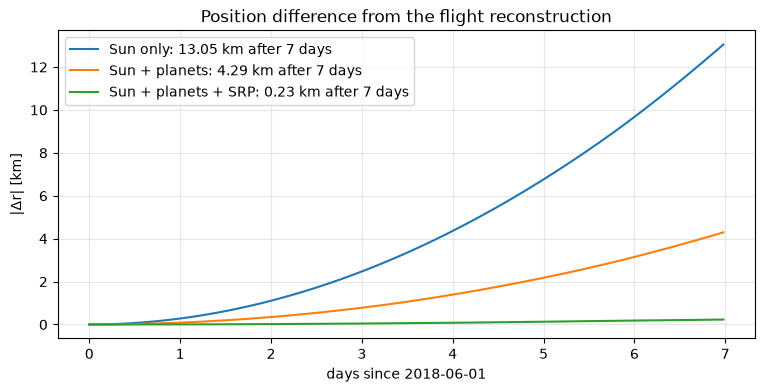

In [7]:
configurations = {
    "Sun only": dict(),
    "Sun + planets": dict(third_bodies=planets),
    "Sun + planets + SRP": dict(third_bodies=planets, cannonball_SRP=True),
}

# 🔵 TODO: Replace the loops with a vectorized approach once get_state accepts an EpochArray
r_flight = [
    orex_flight.get_state(t, reference_frame="J2000", origin="SUN").quantity[:3]
    for t in epochs
]
days = (epochs - epochs[0]).convert_to(day).values

fig, ax = plt.subplots(figsize=(9, 4))
for label, options in configurations.items():
    prop = scb.Propagator(
        primary_body=orex,
        state_vector=x0_state,
        tspan=epochs,
        force_models=scb.ForceModelTranslation(orex, **options),
        propagate_STM=False,
        display_progress=False,
    )
    prop.propagate()
    r_model = scb.Trajectory(state_array=prop.propagated_state_array).position
    dr = [(r_model[i] - r_flight[i]).norm().values for i in range(epochs.size)]
    ax.plot(days, dr, label=f"{label}: {float(dr[-1]):.2f} km after 7 days")
ax.set(
    xlabel="days since 2018-06-01",
    ylabel="|Δr| [km]",
    title="Position difference from the flight reconstruction",
)
ax.legend()
ax.grid(alpha=0.3)

Planetary perturbations reduce the error of a pure two-body model by a factor of three. Because the propagation is Sun-centered, even Mercury matters here: its pull on the Sun (the indirect term, about $6\times10^{-12}$ km/s²) alone accounts for more than a kilometer over the week. SRP accounts for most of the remainder; the modeled acceleration is only about $2\times10^{-11}$ km/s², yet it produces kilometers of drift in a week. The remaining few hundred meters reflect modeling the flight team performed in more detail, for example an attitude-dependent SRP model, and the fact that the SRP parameters above were chosen by hand. Orbit determination faces the same issue from the other side: dynamics mismatches of this size are absorbed into the estimate unless they are modeled or estimated, which chapter 8 addresses.

## 6. Saving the truth

`write_to_spk` saves the propagated states to an SPK file. SPICE returns the stored states at the sample epochs and interpolates between them with Hermite polynomials (SPK type 13), which use both the stored positions and velocities, so the interpolated velocity is the derivative of the interpolated position. If the state contains parameters or the trajectory carries propagator settings, JSON sidecar files with the same base name are written alongside; this state has neither.
<div style="border-left:4px solid #ea580c; background:rgba(234,88,12,0.12); padding:6px 10px; border-radius:4px">
🟠 <b>CHECK:</b> is the user warned if the grid is too sparse for accurate interpolation?
</div>

In [8]:
truth.write_to_spk(str(out / "truth.bsp"))
print(sorted(p.name for p in out.iterdir()))

['truth.bsp']


Once the SPK is loaded, the truth spacecraft can be queried like any other body, and any SPICE-based tool can read the file:

In [9]:
scb.SpiceManager.load_kernel(str(out / "truth.bsp"))

t_mid = epochs[epochs.size // 2]
print(
    "from SPICE:     ",
    orex.get_state(t_mid, reference_frame="J2000", origin="SUN").quantity[:3],
)
print("from Trajectory:", truth.position[epochs.size // 2])

from SPICE:      [-7.93364267e+07 -1.55116557e+08 -8.88015483e+07] [km ... km]
from Trajectory: [-7.93364267e+07 -1.55116557e+08 -8.88015483e+07] [km ... km]


## Summary

| Concept | Scarabaeus API |
|---|---|
| State definition | `StateDefinition().position(...).velocity(...)`, estimation/dynamics flags |
| State vector at an epoch | `StateArray(epoch, origin, state)`, `index_rep` |
| Force model | `ForceModelTranslation(sc, third_bodies=..., cannonball_SRP=...)` |
| Propagation | `Propagator(...)`, `propagate()`, `propagate_STM`, `integrator` |
| Trajectory access | `Trajectory(state_array=...)`, `.position`, `.velocity`, `.epoch` |
| SPK output | `Trajectory.write_to_spk`, `SpiceManager.load_kernel` |

The truth trajectory is saved to `outputs/02_truth_dynamics/truth.bsp` under SPICE ID `-64000`.

<div style="border-left:4px solid #2563eb; background:rgba(37,99,235,0.12); padding:6px 10px; border-radius:4px">
🔵 <b>TODO:</b> **Next:** 3. Tracking data I simulates DSN range and range-rate measurements of this trajectory.
</div>